# 05 - Composições mensais Landsat 5/7/8/9 (30 m)

| | |
|---|---|
| **Tarefa do plano** | S1-07 - composições mensais Landsat 2006-2026 com máscara de nuvens + contagem de observações válidas |
| **Variáveis (Parte I)** | #4-#7 Landsat 5, 7, 8, 9 (bandas para os índices #12-#16, derivados na semana 2) |
| **Fonte** | USGS Landsat Collection 2 Level-2 (refletância de superfície) via Earth Engine |
| **Saída** | `data/raw/optical/landsat/<ano>/` |

Receita (`ete.datasets.landsat_builder`):

- máscara `QA_PIXEL`: preenchimento, nuvem dilatada, cirros, nuvem, sombra de nuvem; mais a saturação `QA_RADSAT`
- conversão para refletância de superfície (0-1)
- harmonização de Roy et al. (2016) **desligada** (`harmonize_tm_etm_to_oli: false` no config): medida sobre a AOI, baixava o MNDWI da água do Landsat 7 de 0,68 para 0,16; sem ela, Landsat 7 e 8 concordam sobre a água
- **mediana** mensal de todos os píxeis limpos, com cada sensor limitado ao seu intervalo de pesquisa no plano
- banda `n_obs` = número de observações limpas por píxel

Bandas: `blue, green, red, nir, swir1, swir2, n_obs`. Os píxeis nunca observados
num mês ficam como nodata (-9999): não são preenchidos.

Correr primeiro `00_setup_and_authentication` e `01_study_area_aoi`. Todos os
downloads podem ser retomados: os ficheiros que já existem são saltados, e cada
ficheiro fica registado em `data/metadata/download_manifest.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import ee
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, datasets, gee, series
from ete import grid as G

cfg = config.load_config()
gee.init(cfg)

aoi = G.load_aoi(cfg)                       # AOI das imagens (EPSG:4326)
region = gee.ee_geometry(aoi)
grid30 = G.load_grid(cfg)                   # grelha do projeto a 30 m (EPSG:32736)
grid10 = G.load_grid(cfg, 10)               # grelha a 10 m, encaixada na de 30 m
climate_bounds = tuple(G.load_aoi(cfg, "aoi_climate").total_bounds)   # O, S, E, N
MASK = gee.ee_geometry(G.imagery_mask(cfg))  # distrito + margem: fora daqui as imagens mensais ficam sem dados

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## Parâmetros

**Formato dos ficheiros.** Os valores são guardados como inteiros (`DTYPE`), multiplicados
por `SCALE`, para ocupar menos disco e menos internet sem perda relevante de precisão.
O fator fica gravado dentro do GeoTIFF: ler sempre com `series.read_scaled(ficheiro)`,
que devolve os valores físicos. As bandas `n_obs` e `label_mode` não são multiplicadas.
Com `MASK`, os píxeis fora do distrito + margem ficam sem dados (-9999).

In [2]:
ds = cfg["datasets"]["landsat"]
DATASET, SOURCE_ID = "landsat", "LANDSAT/{LT05,LE07,LC08,LC09}/C02/T1_L2"
BANDS = ds["bands"] + ["n_obs"]
GRID, DTYPE, START = grid30, "int16", ds["start"]
SCALE = 10000                               # refletância guardada como inteiro (x10000)
OUT_DIR = config.path(cfg, "landsat")
builder = datasets.landsat_builder(cfg, region)
print("harmonizado para OLI:", ds["harmonize_tm_etm_to_oli"])

harmonizado para OLI: False


## Teste com um mês

Correr sempre um mês primeiro e observá-lo antes de lançar o período completo.
`2013-01` está na época chuvosa, quando as nuvens e as cheias são mais prováveis.

In [3]:
TEST_MONTH = "2013-01"
test = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR,
                            start=f"{TEST_MONTH}-01", end=f"{TEST_MONTH}-28", dtype=DTYPE, scale=SCALE, mask=MASK)
test

landsat:   0%|          | 0/1 [00:00<?, ?it/s]

,period,status,file
0,2013-01,exists,landsat_marracuene_2013-01_30m.tif


('blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'n_obs') int16 EPSG:32736 (30.0, 30.0) (1804, 1748)
tamanho em disco: 2 MB
píxeis sem nenhuma observação limpa: 90.9%


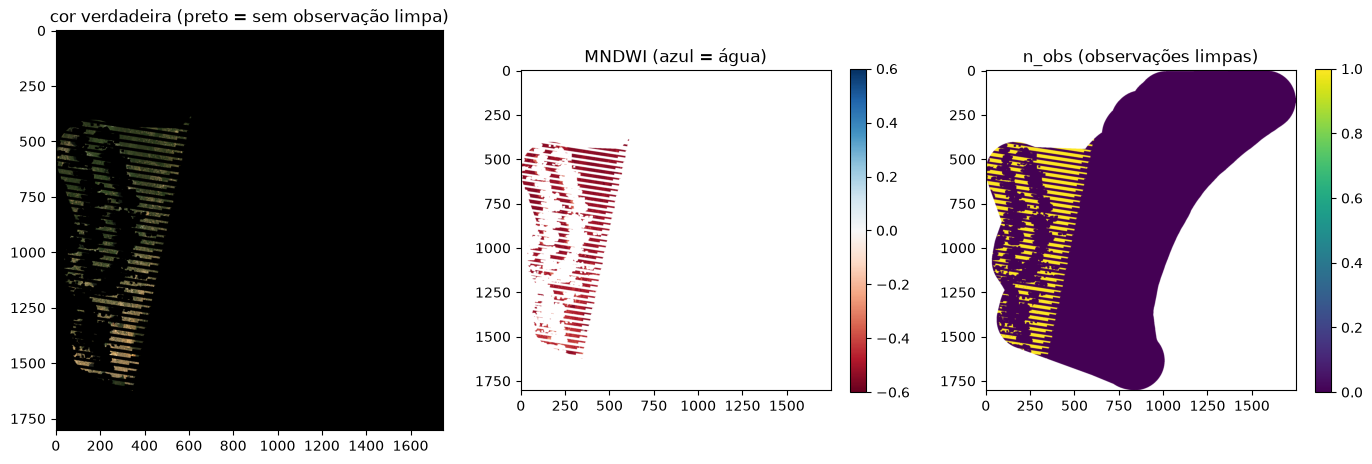

In [4]:
import numpy as np
import rasterio

test_file = next(OUT_DIR.rglob(f"*_{TEST_MONTH}_*.tif"))
with rasterio.open(test_file) as src:
    print(src.descriptions, src.dtypes[0], src.crs, src.res, src.shape)
print(f"tamanho em disco: {test_file.stat().st_size / 1e6:.0f} MB")
data, _ = series.read_scaled(test_file)      # valores físicos (refletância 0-1)
rgb = np.clip(np.ma.filled(data[[2, 1, 0]], 0).transpose(1, 2, 0) / 0.25, 0, 1)
green, swir1, n_obs = data[BANDS.index("green")], data[BANDS.index("swir1")], data[-1]
mndwi = (green - swir1) / (green + swir1)

fig, axes = plt.subplots(1, 3, figsize=(17, 7))
axes[0].imshow(rgb); axes[0].set_title("cor verdadeira (preto = sem observação limpa)")
im = axes[1].imshow(mndwi, cmap="RdBu", vmin=-0.6, vmax=0.6); axes[1].set_title("MNDWI (azul = água)"); plt.colorbar(im, ax=axes[1], shrink=0.6)
im = axes[2].imshow(n_obs, cmap="viridis"); axes[2].set_title("n_obs (observações limpas)"); plt.colorbar(im, ax=axes[2], shrink=0.6)
print(f"píxeis sem nenhuma observação limpa: {(n_obs == 0).mean():.1%}")

## Período completo

Demora bastante (horas para os datasets de 10 m). Pode ser interrompido e
retomado a qualquer momento; os meses já concluídos são saltados.

In [5]:
log = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR, start=START, dtype=DTYPE, scale=SCALE, mask=MASK)
log["status"].value_counts()

landsat:   0%|          | 0/249 [00:00<?, ?it/s]

status
downloaded    225
absent         14
exists         10
Name: count, dtype: int64

## Inventário

In [6]:
inv = series.monthly_inventory(OUT_DIR)
expected = [m.strftime("%Y-%m") for m in gee.month_starts(START, config.period_end(cfg))]
missing = sorted(set(expected) - set(inv["period"]))
print(f"{len(inv)} ficheiros, {inv['size_mb'].sum() / 1e3:.2f} GB em disco")
print(f"{len(missing)} de {len(expected)} meses sem ficheiro (ausentes na fonte ou com falha):")
print(missing)

235 ficheiros, 2.64 GB em disco
14 de 249 meses sem ficheiro (ausentes na fonte ou com falha):
['2006-11', '2007-11', '2008-06', '2008-07', '2008-12', '2009-01', '2009-06', '2009-07', '2009-08', '2009-09', '2010-04', '2010-11', '2011-01', '2011-07']
